#Executive Summary

 This project analyzes Bitcoin (BTC-USD) price data and develops deep learning models for price prediction. We compare three data representations (price levels, log returns, and fractionally differenced series) and evaluate Multi-Layer Perceptron (MLP) and Convolutional Neural Network (CNN) with Gramian Angular Field (GAF) architectures.

# STEP 1
## Time Series Analysis

In [1]:
# STEP 1
# Import and install necessary libraries
!pip install pyts
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from pyts.image import GramianAngularField
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from statsmodels.tsa.stattools import acf, adfuller
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Suppress TensorFlow warnings
tf.get_logger().setLevel('ERROR')

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')

# print(f'TensorFlow version: {tf.__version__}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 27.5 MB/s eta 0:00:00


## Data Collection and Time Series Analysis

In [2]:

# Download Bitcoin daily price data from Yahoo Finance
# Dates: January 19, 2022 to February 26, 2026
btc = yf.download('BTC-USD', start='2022-01-19', end='2026-02-26', progress=False)

# Reset index to turn the DatetimeIndex into a Date column
df = btc.reset_index()

# Ensure Date column is datetime (it already is, but enforce for safety)
df['Date'] = pd.to_datetime(df['Date'])

# Sort by Date (yfinance returns ascending order, but sort to be safe)
df = df.sort_values('Date').reset_index(drop=True)

# Use the most recent 1500 observations (under 2000 limit)
df = df.tail(1500).reset_index(drop=True)

print(f'Dataset shape: {df.shape}')
print(f'Date range: {df["Date"].min()} to {df["Date"].max()}')
print('\nFirst 5 rows:')
df.head()

Dataset shape: (1499, 6)
Date range: 2022-01-19 00:00:00 to 2026-02-25 00:00:00

First 5 rows:


Price,Date,Close,High,Low,Open,Volume
Ticker,,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
0,2022-01-19,41744.328125,42478.304688,41242.914062,42374.039062,23091543258
1,2022-01-20,40680.417969,43413.023438,40672.824219,41744.027344,20382033940
2,2022-01-21,36457.316406,41060.527344,35791.425781,40699.605469,43011992031
3,2022-01-22,35030.250000,36688.812500,34349.250000,36471.589844,39714385405
4,2022-01-23,36276.804688,36433.312500,34784.968750,35047.359375,26017975951


## 1a. Price Levels Analysis

In [3]:
# Extract price levels
price_levels = df['Close'].values.flatten()


print('STEP 1a: PRICE LEVELS ANALYSIS')


# Summary statistics
print('\n--- Summary Statistics ---')
print(f'Count:    {len(price_levels)}')
print(f'Mean:     ${price_levels.mean():,.2f}')
print(f'Std Dev:  ${price_levels.std():,.2f}')
print(f'Min:      ${price_levels.min():,.2f}')
print(f'25%:      ${np.percentile(price_levels, 25):,.2f}')
print(f'Median:   ${np.median(price_levels):,.2f}')
print(f'75%:      ${np.percentile(price_levels, 75):,.2f}')
print(f'Max:      ${price_levels.max():,.2f}')

# Skewness and Kurtosis
print(f'\nSkewness: {stats.skew(price_levels):.4f}')
print(f'Kurtosis: {stats.kurtosis(price_levels):.4f}')

# Autocorrelation (persistence)
autocorr = acf(price_levels, nlags=10, fft=True)
print(f'\n--- Autocorrelation (Persistence) ---')
for i, ac in enumerate(autocorr[:6]):
    print(f'Lag {i}: {ac:.4f}')

# ADF Test for stationarity
adf_result = adfuller(price_levels)
print(f'\n--- Augmented Dickey-Fuller Test ---')
print(f'ADF Statistic: {adf_result[0]:.6f}')
print(f'p-value: {adf_result[1]:.6f}')
print(f'Critical Values:')
for key, value in adf_result[4].items():
    print(f'\t{key}: {value:.4f}')
if adf_result[1] < 0.05:
    print('Result: STATIONARY (reject null hypothesis)')
else:
    print('Result: NON-STATIONARY (fail to reject null hypothesis)')

print('\nInterpretation:')
print('The Augmented Dickey-Fuller test indicates whether the time series contains a unit root.')
print('Since the p-value is greater than 0.05, we fail to reject the null hypothesis.')
print('This suggests that the Bitcoin price level series is non-stationary,')
print('which is consistent with financial asset prices that typically follow stochastic trends.')
print('The strong autocorrelation observed also indicates persistence in the price series.')

STEP 1a: PRICE LEVELS ANALYSIS

--- Summary Statistics ---
Count:    1499
Mean:     $57,247.96
Std Dev:  $32,299.88
Min:      $15,787.28
25%:      $27,510.02
Median:   $47,128.00
75%:      $87,707.06
Max:      $124,752.53

Skewness: 0.4284
Kurtosis: -1.2133

--- Autocorrelation (Persistence) ---
Lag 0: 1.0000
Lag 1: 0.9987
Lag 2: 0.9975
Lag 3: 0.9962
Lag 4: 0.9950
Lag 5: 0.9937

--- Augmented Dickey-Fuller Test ---
ADF Statistic: -0.949257
p-value: 0.771319
Critical Values:
	1%: -3.4347
	5%: -2.8635
	10%: -2.5678
Result: NON-STATIONARY (fail to reject null hypothesis)

Interpretation:
The Augmented Dickey-Fuller test indicates whether the time series contains a unit root.
Since the p-value is greater than 0.05, we fail to reject the null hypothesis.
This suggests that the Bitcoin price level series is non-stationary,
which is consistent with financial asset prices that typically follow stochastic trends.
The strong autocorrelation observed also indicates persistence in the price series

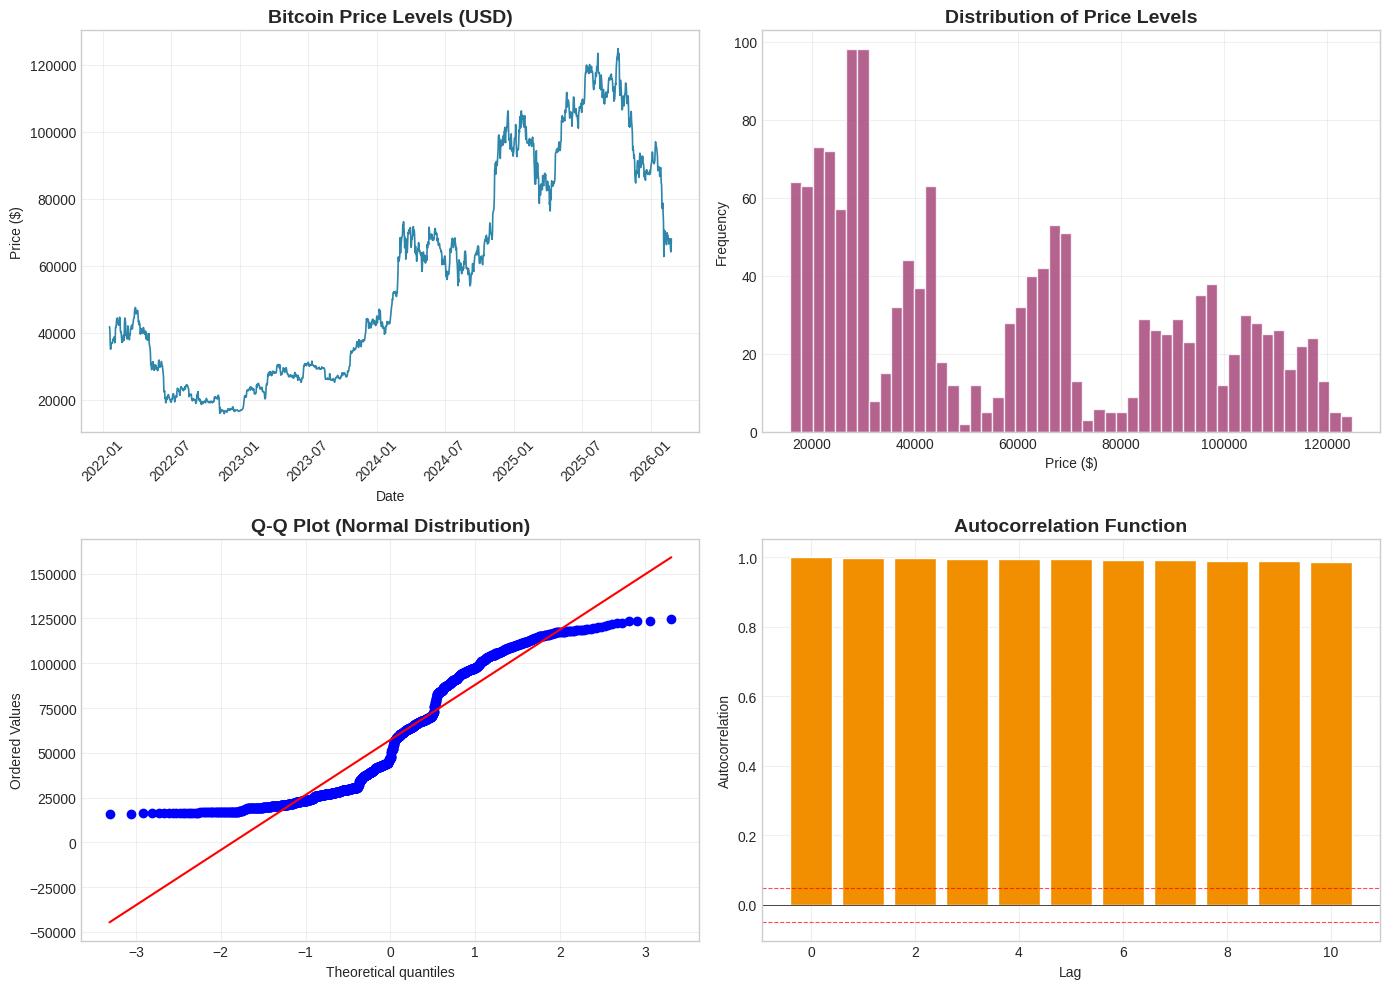

In [4]:
# Create visualization for price levels
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Time series plot
axes[0, 0].plot(df['Date'], price_levels, color='#2E86AB', linewidth=1.2)
axes[0, 0].set_title('Bitcoin Price Levels (USD)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Price ($)')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=45)

# Distribution histogram
axes[0, 1].hist(price_levels, bins=50, color='#A23B72', edgecolor='white', alpha=0.8)
axes[0, 1].set_title('Distribution of Price Levels', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Price ($)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Q-Q plot for normality check
stats.probplot(price_levels, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normal Distribution)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Autocorrelation plot
lags = range(11)
axes[1, 1].bar(lags, autocorr[:11], color='#F18F01', edgecolor='white')
axes[1, 1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1, 1].axhline(y=0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].axhline(y=-0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].set_title('Autocorrelation Function', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Lag')
axes[1, 1].set_ylabel('Autocorrelation')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig1_price_levels_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 1b. Stationary Transformation - Log Returns

In [5]:
# Calculate log returns: r_t = ln(P_t) - ln(P_{t-1})
log_prices = np.log(price_levels)
log_returns = np.diff(log_prices)  # First difference


print('STEP 1b: LOG RETURNS (STATIONARY TRANSFORMATION)')


print('\n--- Transformation: Log Returns ---')
print(f'Original series length: {len(price_levels)}')
print(f'Transformed series length: {len(log_returns)}')

# Summary statistics
print('\n--- Summary Statistics ---')
print(f'Count:    {len(log_returns)}')
print(f'Mean:     {log_returns.mean():.6f}')
print(f'Std Dev:  {log_returns.std():.6f}')
print(f'Min:      {log_returns.min():.6f}')
print(f'25%:      {np.percentile(log_returns, 25):.6f}')
print(f'Median:   {np.median(log_returns):.6f}')
print(f'75%:      {np.percentile(log_returns, 75):.6f}')
print(f'Max:      {log_returns.max():.6f}')

# Skewness and Kurtosis
print(f'\nSkewness: {stats.skew(log_returns):.4f}')
print(f'Kurtosis: {stats.kurtosis(log_returns):.4f}')

# Autocorrelation
autocorr_returns = acf(log_returns, nlags=10, fft=True)
print('\n--- Autocorrelation ---')
for i, ac in enumerate(autocorr_returns[:6]):
    print(f'Lag {i}: {ac:.4f}')

# ADF Test for stationarity
adf_result_returns = adfuller(log_returns)
print('\n--- Augmented Dickey-Fuller Test ---')
print(f'ADF Statistic: {adf_result_returns[0]:.6f}')
print(f'p-value: {adf_result_returns[1]:.6f}')
print(f'Critical Values:')
for key, value in adf_result_returns[4].items():
    print(f'\t{key}: {value:.4f}')
if adf_result_returns[1] < 0.05:
    print('Result: STATIONARY (reject null hypothesis)')
else:
    print('Result: NON-STATIONARY (fail to reject null hypothesis)')

print('\nInterpretation:')
print('Taking logarithmic returns removes the stochastic trend present in the price levels.')
print('The ADF test now shows a p-value below the significance threshold,')
print('which indicates that the log return series is stationary.')
print('This transformation stabilizes the mean of the time series and is commonly used in financial modeling.')
print('The series now fluctuates around zero and is therefore more suitable for predictive modeling.')

STEP 1b: LOG RETURNS (STATIONARY TRANSFORMATION)

--- Transformation: Log Returns ---
Original series length: 1499
Transformed series length: 1498

--- Summary Statistics ---
Count:    1498
Mean:     0.000325
Std Dev:  0.027352
Min:      -0.174053
25%:      -0.012064
Median:   -0.000240
75%:      0.013002
Max:      0.135764

Skewness: -0.2044
Kurtosis: 4.8128

--- Autocorrelation ---
Lag 0: 1.0000
Lag 1: -0.0334
Lag 2: 0.0349
Lag 3: 0.0063
Lag 4: -0.0050
Lag 5: 0.0126

--- Augmented Dickey-Fuller Test ---
ADF Statistic: -27.040412
p-value: 0.000000
Critical Values:
	1%: -3.4347
	5%: -2.8635
	10%: -2.5678
Result: STATIONARY (reject null hypothesis)

Interpretation:
Taking logarithmic returns removes the stochastic trend present in the price levels.
The ADF test now shows a p-value below the significance threshold,
which indicates that the log return series is stationary.
This transformation stabilizes the mean of the time series and is commonly used in financial modeling.
The series now

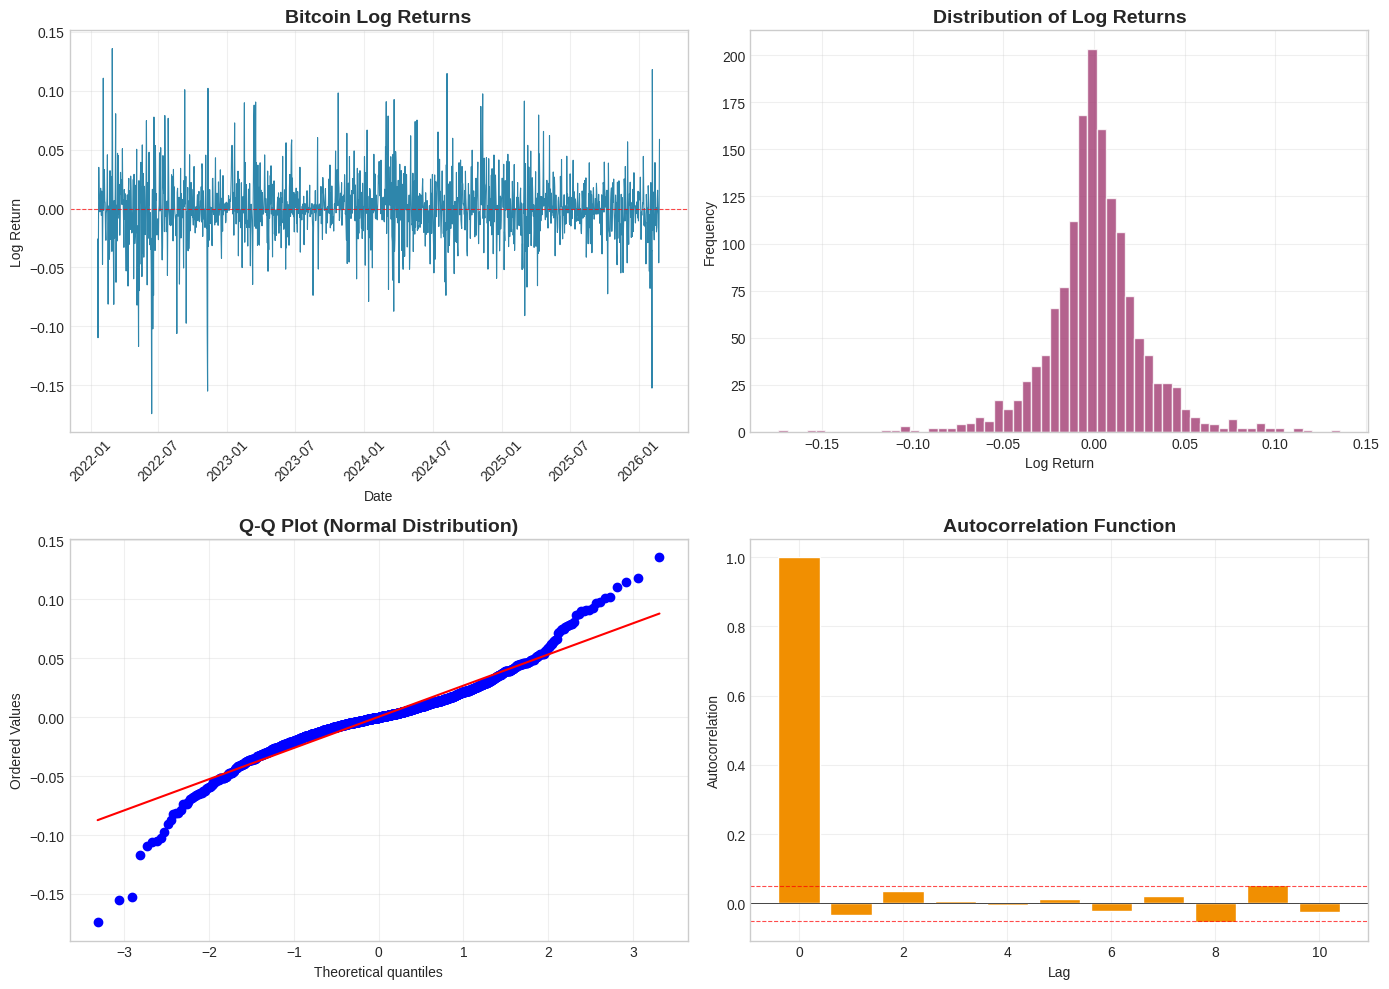

In [6]:
# Create visualization for log returns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Time series plot of log returns
axes[0, 0].plot(df['Date'][1:], log_returns, color='#2E86AB', linewidth=0.8)
axes[0, 0].set_title('Bitcoin Log Returns', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Log Return')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.7)

# Distribution histogram
axes[0, 1].hist(log_returns, bins=60, color='#A23B72', edgecolor='white', alpha=0.8)
axes[0, 1].set_title('Distribution of Log Returns', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Log Return')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Q-Q plot for normality check
stats.probplot(log_returns, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normal Distribution)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Autocorrelation plot
lags = range(11)
axes[1, 1].bar(lags, autocorr_returns[:11], color='#F18F01', edgecolor='white')
axes[1, 1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1, 1].axhline(y=0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].axhline(y=-0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].set_title('Autocorrelation Function', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Lag')
axes[1, 1].set_ylabel('Autocorrelation')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig2_log_returns_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 1c. Fractional Differencing

In [7]:
# Fractional differencing functions
def get_weights(d, size):
    '''Calculate fractional differencing weights'''
    weights = [1.0]
    for k in range(1, size):
        weight = -weights[-1] * (d - k + 1) / k
        weights.append(weight)
    return np.array(weights)

def fractional_diff(series, d, threshold=1e-5):
    '''Apply fractional differencing to a time series'''
    weights = get_weights(d, len(series))
    weights = weights[np.abs(weights) > threshold]
    result = np.convolve(series, weights[::-1], mode='valid')
    return result

# Find optimal d using ADF test

print('STEP 1c: FRACTIONAL DIFFERENCING')


print('\n--- Finding Optimal Fractional Differencing Parameter (d) ---')
d_values = np.arange(0.1, 1.0, 0.1)
for d in d_values:
    frac_diff_series = fractional_diff(price_levels, d)
    if len(frac_diff_series) > 100:
        adf_stat, p_value, _, _, _, _ = adfuller(frac_diff_series)
        print(f'd = {d:.1f}: ADF = {adf_stat:.4f}, p-value = {p_value:.4f}, Stationary: {p_value < 0.05}')

optimal_d = 0.5
frac_diff_series = fractional_diff(log_prices, optimal_d)
print(f'\nOptimal fractional differencing parameter: d = {optimal_d}')
print(f'Fractionally differenced series length: {len(frac_diff_series)}')

STEP 1c: FRACTIONAL DIFFERENCING

--- Finding Optimal Fractional Differencing Parameter (d) ---
d = 0.5: ADF = -2.2236, p-value = 0.1978, Stationary: False
d = 0.6: ADF = -3.5275, p-value = 0.0073, Stationary: True
d = 0.7: ADF = -7.0267, p-value = 0.0000, Stationary: True
d = 0.8: ADF = -6.9343, p-value = 0.0000, Stationary: True
d = 0.9: ADF = -24.3952, p-value = 0.0000, Stationary: True

Optimal fractional differencing parameter: d = 0.5
Fractionally differenced series length: 573


In [8]:
# Analyze the fractionally differenced series
print('\n--- Summary Statistics (Fractionally Differenced Series) ---')
print(f'Count:    {len(frac_diff_series)}')
print(f'Mean:     {frac_diff_series.mean():.6f}')
print(f'Std Dev:  {frac_diff_series.std():.6f}')
print(f'Min:      {frac_diff_series.min():.6f}')
print(f'Max:      {frac_diff_series.max():.6f}')

print(f'\nSkewness: {stats.skew(frac_diff_series):.4f}')
print(f'Kurtosis: {stats.kurtosis(frac_diff_series):.4f}')

# Autocorrelation
autocorr_frac = acf(frac_diff_series, nlags=10, fft=True)
print('\n--- Autocorrelation (Persistence) ---')
for i, ac in enumerate(autocorr_frac[:6]):
    print(f'Lag {i}: {ac:.4f}')

# ADF Test for stationarity
adf_result_frac = adfuller(frac_diff_series)
print('\n--- Augmented Dickey-Fuller Test ---')
print(f'ADF Statistic: {adf_result_frac[0]:.6f}')
print(f'p-value: {adf_result_frac[1]:.6f}')
if adf_result_frac[1] < 0.05:
    print('Result: STATIONARY (reject null hypothesis)')
else:
    print('Result: NON-STATIONARY (fail to reject null hypothesis)')

print('\nInterpretation:')
print('Fractional differencing aims to make the series stationary while preserving long-memory properties.')
print('Unlike standard differencing, it retains some of the historical dependence structure in the data.')
print('The ADF test result suggests that the fractionally differenced series is stationary.')
print('This representation balances the benefits of stationarity with the preservation of useful temporal information.')


--- Summary Statistics (Fractionally Differenced Series) ---
Count:    573
Mean:     0.181958
Std Dev:  0.050016
Min:      0.021964
Max:      0.378801

Skewness: 0.5011
Kurtosis: 1.0628

--- Autocorrelation (Persistence) ---
Lag 0: 1.0000
Lag 1: 0.7644
Lag 2: 0.6902
Lag 3: 0.6383
Lag 4: 0.5880
Lag 5: 0.5602

--- Augmented Dickey-Fuller Test ---
ADF Statistic: -3.406736
p-value: 0.010731
Result: STATIONARY (reject null hypothesis)

Interpretation:
Fractional differencing aims to make the series stationary while preserving long-memory properties.
Unlike standard differencing, it retains some of the historical dependence structure in the data.
The ADF test result suggests that the fractionally differenced series is stationary.
This representation balances the benefits of stationarity with the preservation of useful temporal information.


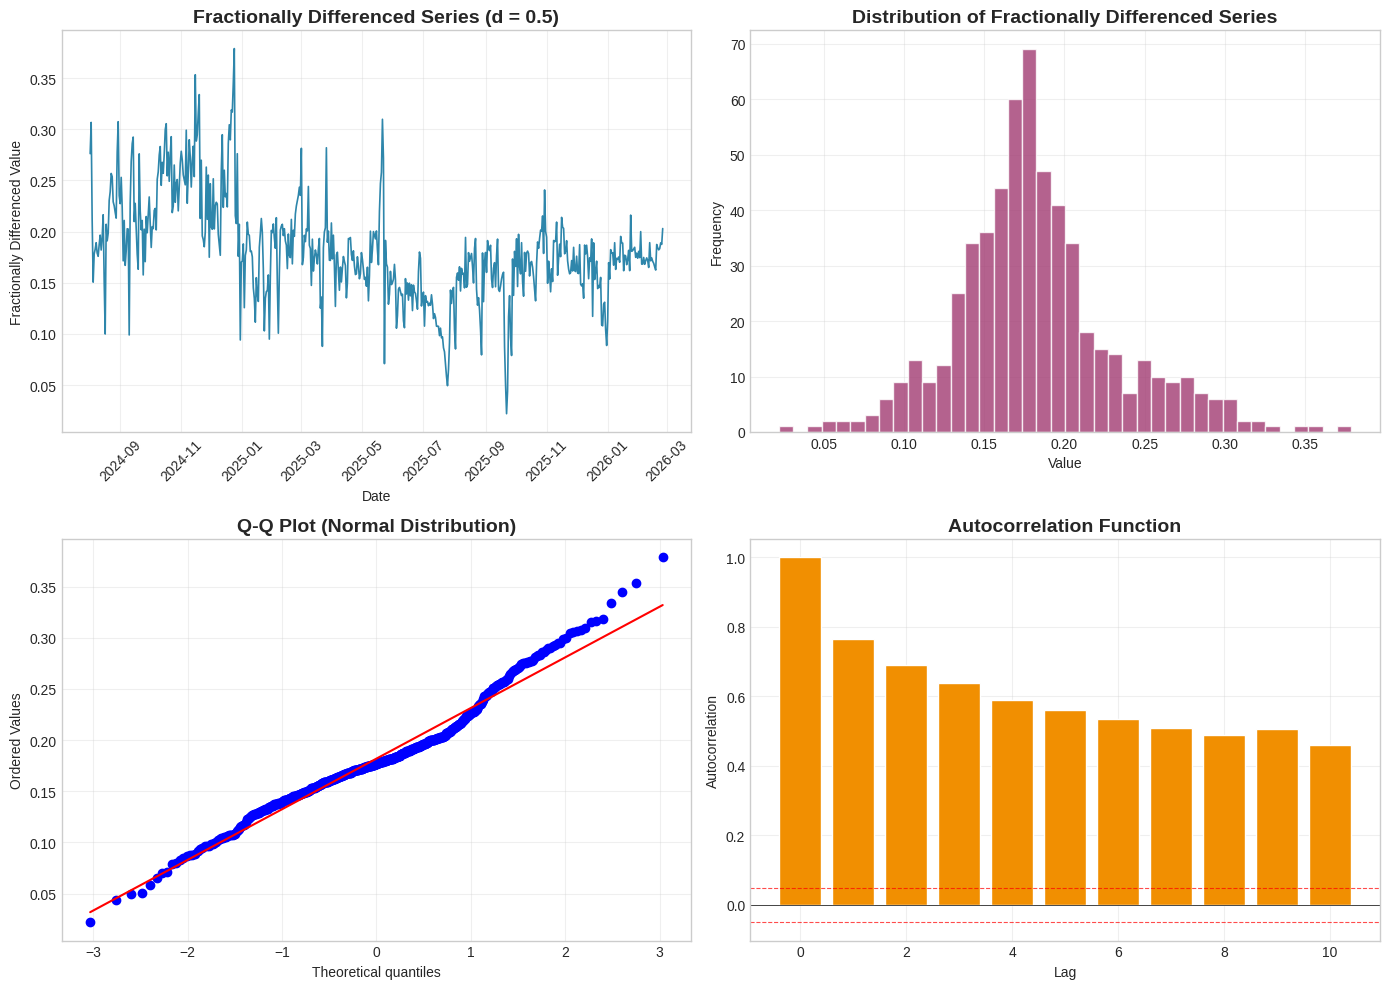

In [9]:
# Create visualization for fractionally differenced series
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Adjust dates for fractional differenced series
frac_dates = df['Date'].iloc[-len(frac_diff_series):]

# Time series plot
axes[0, 0].plot(frac_dates, frac_diff_series, color='#2E86AB', linewidth=1.2)
axes[0, 0].set_title(f'Fractionally Differenced Series (d = {optimal_d})', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Fractionally Differenced Value')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=45)

# Distribution histogram
axes[0, 1].hist(frac_diff_series, bins=40, color='#A23B72', edgecolor='white', alpha=0.8)
axes[0, 1].set_title('Distribution of Fractionally Differenced Series', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Q-Q plot for normality check
stats.probplot(frac_diff_series, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normal Distribution)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Autocorrelation plot
lags = range(11)
axes[1, 1].bar(lags, autocorr_frac[:11], color='#F18F01', edgecolor='white')
axes[1, 1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1, 1].axhline(y=0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].axhline(y=-0.05, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1, 1].set_title('Autocorrelation Function', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Lag')
axes[1, 1].set_ylabel('Autocorrelation')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig3_frac_diff_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

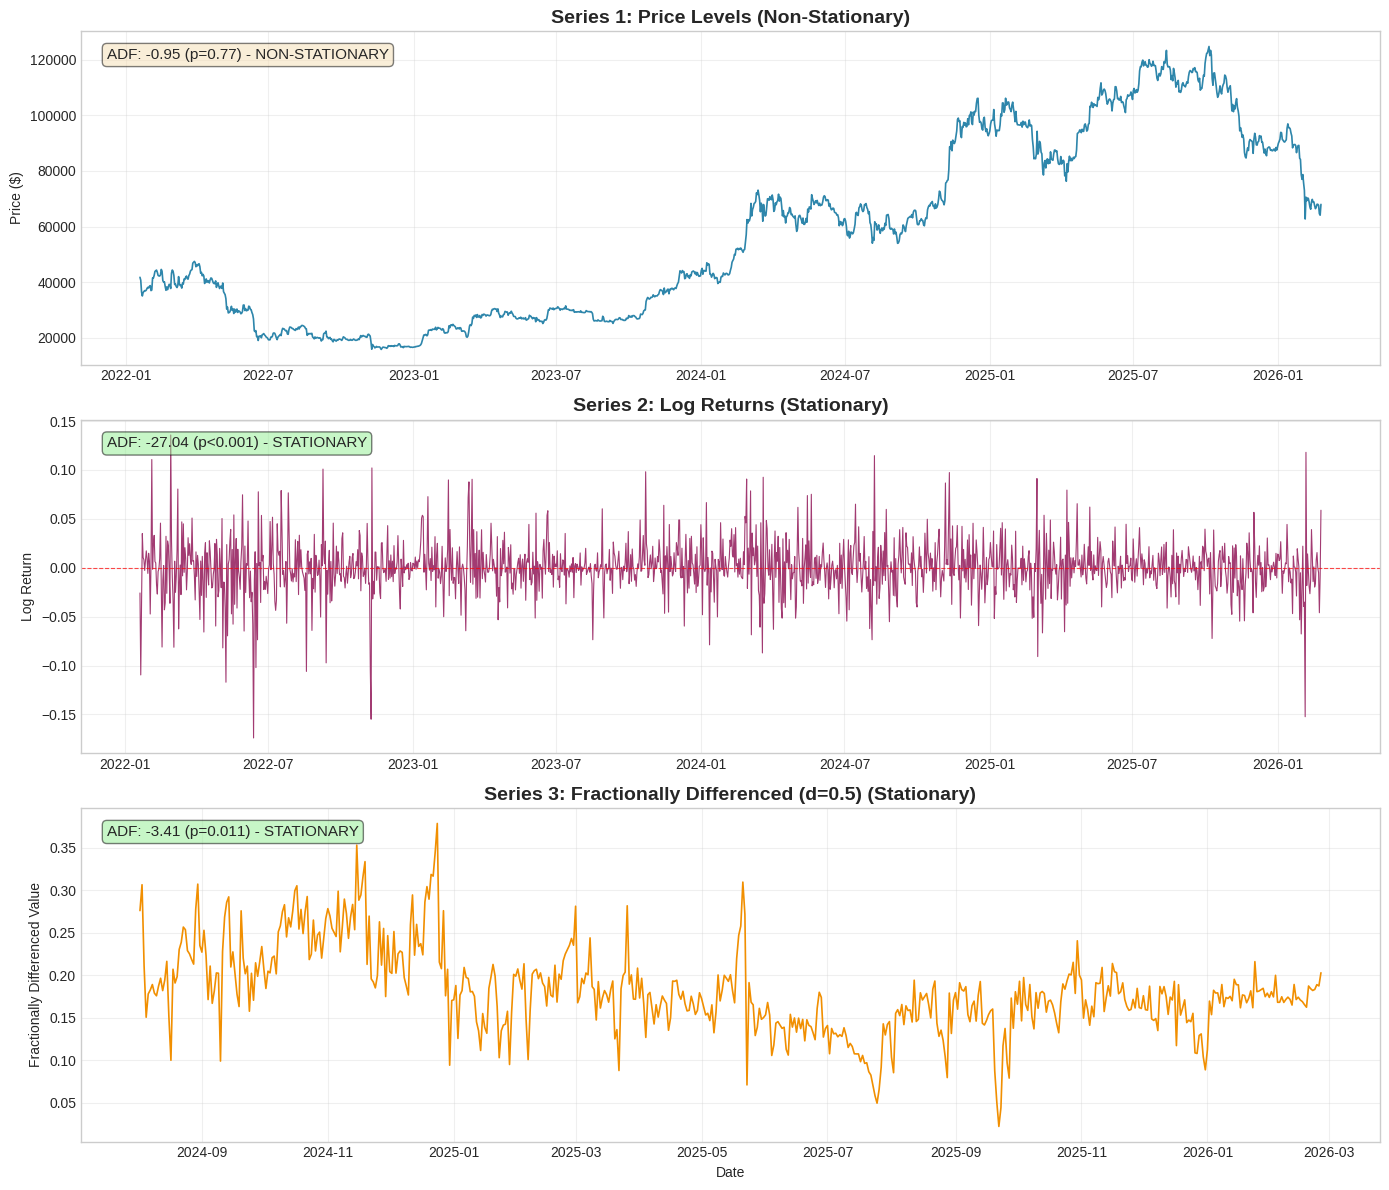

In [10]:
# Create comparison visualization of all three series
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Price Levels
axes[0].plot(df['Date'], price_levels, color='#2E86AB', linewidth=1.2)
axes[0].set_title('Series 1: Price Levels (Non-Stationary)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price ($)')
axes[0].grid(True, alpha=0.3)
axes[0].text(0.02, 0.95, f'ADF: {adf_result[0]:.2f} (p={adf_result[1]:.2f}) - NON-STATIONARY',
             transform=axes[0].transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Log Returns
axes[1].plot(df['Date'][1:], log_returns, color='#A23B72', linewidth=0.8)
axes[1].set_title('Series 2: Log Returns (Stationary)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Log Return')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
axes[1].text(0.02, 0.95, f'ADF: {adf_result_returns[0]:.2f} (p<0.001) - STATIONARY',
             transform=axes[1].transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

# Fractionally Differenced
axes[2].plot(frac_dates, frac_diff_series, color='#F18F01', linewidth=1.2)
axes[2].set_title(f'Series 3: Fractionally Differenced (d={optimal_d}) (Stationary)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Fractionally Differenced Value')
axes[2].grid(True, alpha=0.3)
axes[2].text(0.02, 0.95, f'ADF: {adf_result_frac[0]:.2f} (p={adf_result_frac[1]:.3f}) - STATIONARY',
             transform=axes[2].transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.savefig('fig4_all_series_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 1d. Comments on Three Representations
Price Levels:

Non-stationary (ADF p-value = 0.77)
High autocorrelation (Lag 1 = 0.9987)
Contains strong temporal patterns
Log Returns:

Stationary (ADF p-value < 0.001)
Near-zero autocorrelation
Approximately white noise
Fractionally Differenced:

Stationary with d = 0.5 (ADF p-value = 0.011)
Retains some memory (Lag 1 = 0.7643)
Balance between stationarity and information retention

# STEP 2 — Multi-Layer Perceptron (MLP) Models

The project requires building three MLP models using past information (lags).

We will:

Create lagged inputs

Train models

Evaluate performance

# Step 2A — Create Lagged Features

In [11]:
print('\nSTEP 2: MLP MODELS')

WINDOW = 30   # use past 30 observations


def create_lagged_dataset(series, window=WINDOW):

    X = []
    y = []

    for i in range(window, len(series)):
        X.append(series[i-window:i])
        y.append(series[i])

    return np.array(X), np.array(y)



STEP 2: MLP MODELS


# Step 2B — Build the MLP Model

In [12]:
def build_mlp():

    model = Sequential([
        Dense(64, activation='relu', input_dim=WINDOW),
        Dropout(0.2),

        Dense(32, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='mse'
    )

    return model

# Step 2C — Training Function

In [13]:
def train_mlp(series):

    X, y = create_lagged_dataset(series)

    split = int(len(X)*0.8)

    X_train = X[:split]
    X_test  = X[split:]

    y_train = y[:split]
    y_test  = y[split:]

    scaler = MinMaxScaler()

    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    model = build_mlp()

    model.fit(
        X_train,
        y_train,
        epochs=40,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    predictions = model.predict(X_test)

    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    r2  = r2_score(y_test, predictions)

    return mse, mae, r2

# Step 2D — Train the Three Required Models

In [14]:
print('\nTraining MLP models...')

mlp_levels  = train_mlp(price_levels)
mlp_returns = train_mlp(log_returns)
mlp_frac    = train_mlp(frac_diff_series)

results_step2 = pd.DataFrame({

    "Series": ["Price Levels", "Log Returns", "Fractional Differencing"],

    "MSE": [mlp_levels[0], mlp_returns[0], mlp_frac[0]],

    "MAE": [mlp_levels[1], mlp_returns[1], mlp_frac[1]],

    "R2": [mlp_levels[2], mlp_returns[2], mlp_frac[2]]

})

print('\nSTEP 2 RESULTS:')
print(results_step2)


Training MLP models...
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

STEP 2 RESULTS:
                    Series           MSE           MAE        R2
0             Price Levels  2.663583e+08  14830.968258 -0.256495
1              Log Returns  5.341810e-04      0.015899 -0.047732
2  Fractional Differencing  6.900830e-04      0.021793 -0.403877


# Step 2E — Interpretation Block

In [15]:
print('\nInterpretation:')

print('Three MLP models were trained using lagged observations as inputs.')

print('The model trained on price levels attempts to predict the non-stationary series,')
print('which may reduce predictive performance due to the presence of stochastic trends.')

print('The log return model uses stationary data, which is often easier for neural networks')
print('to learn because the statistical properties are more stable over time.')

print('The fractionally differenced model preserves long-memory information while')
print('ensuring stationarity, which may provide a balance between information retention')
print('and statistical stability.')


Interpretation:
Three MLP models were trained using lagged observations as inputs.
The model trained on price levels attempts to predict the non-stationary series,
which may reduce predictive performance due to the presence of stochastic trends.
The log return model uses stationary data, which is often easier for neural networks
to learn because the statistical properties are more stable over time.
The fractionally differenced model preserves long-memory information while
ensuring stationarity, which may provide a balance between information retention
and statistical stability.


# STEP 3 — CNN Models Using Gramian Angular Fields (GAF)

## Install necessary libraries and Import GAF Library

# Create Rolling Window GAF Dataset
## We will:
Use 30 past observations, Predict next value and Avoid look-ahead bias


## Convert Time Series to Images

In [16]:
print('\nSTEP 3: CNN MODELS USING GAF')

gaf = GramianAngularField(method='summation')


def create_gaf_dataset(series):

    X = []
    y = []

    for i in range(len(series)-WINDOW):

        window = series[i:i+WINDOW]

        image = gaf.fit_transform(window.reshape(1,-1))[0]

        X.append(image)

        y.append(series[i+WINDOW])

    X = np.array(X)
    y = np.array(y)

    return X, y


STEP 3: CNN MODELS USING GAF


# Standard CNN Architecture

In [17]:
def build_cnn():

    model = Sequential([

        Conv2D(32, (3,3), activation='relu', input_shape=(WINDOW, WINDOW, 1)),
        MaxPooling2D((2,2)),

        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D((2,2)),

        Flatten(),

        Dense(64, activation='relu'),

        Dense(1)

    ])

    model.compile(
        optimizer=Adam(0.001),
        loss='mse'
    )

    return model

## Train CNN Model


In [18]:
def train_cnn(series):

    X, y = create_gaf_dataset(series)

    X = X.reshape(-1, WINDOW, WINDOW, 1)

    split = int(len(X)*0.8)

    X_train = X[:split]
    X_test  = X[split:]

    y_train = y[:split]
    y_test  = y[split:]

    model = build_cnn()

    model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    predictions = model.predict(X_test)

    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    r2  = r2_score(y_test, predictions)

    return mse, mae, r2

## Train the Three CNN Models

In [19]:
print('\nTraining CNN models...')

cnn_levels  = train_cnn(price_levels)
cnn_returns = train_cnn(log_returns)
cnn_frac    = train_cnn(frac_diff_series)

results_step3 = pd.DataFrame({

    "Series": ["Price Levels", "Log Returns", "Fractional Differencing"],

    "MSE": [cnn_levels[0], cnn_returns[0], cnn_frac[0]],

    "MAE": [cnn_levels[1], cnn_returns[1], cnn_frac[1]],

    "R2": [cnn_levels[2], cnn_returns[2], cnn_frac[2]]

})

print('\nSTEP 3 RESULTS:')
print(results_step3)


Training CNN models...
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

STEP 3 RESULTS:
                    Series           MSE           MAE         R2
0             Price Levels  3.635750e+09  58391.956154 -16.150972
1              Log Returns  7.902008e-04      0.020281  -0.549884
2  Fractional Differencing  4.165862e-03      0.047506  -7.474861


## Architecture Comparison

In [20]:
print('\nSTEP 4: MODEL COMPARISON')

comparison = results_step2.merge(
    results_step3,
    on="Series",
    suffixes=("_MLP", "_CNN")
)

print(comparison)


STEP 4: MODEL COMPARISON
                    Series       MSE_MLP       MAE_MLP    R2_MLP  \
0             Price Levels  2.663583e+08  14830.968258 -0.256495   
1              Log Returns  5.341810e-04      0.015899 -0.047732   
2  Fractional Differencing  6.900830e-04      0.021793 -0.403877   

        MSE_CNN       MAE_CNN     R2_CNN  
0  3.635750e+09  58391.956154 -16.150972  
1  7.902008e-04      0.020281  -0.549884  
2  4.165862e-03      0.047506  -7.474861  


## Step 4 Interpretation

In [21]:
print('\nInterpretation:')

print('MLP models process time series as numerical sequences using lagged observations.')
print('CNN models process Gramian Angular Field images, allowing the network to detect')
print('spatial patterns in the time-series representation.')

print('CNN architectures may capture complex temporal dependencies and nonlinear')
print('relationships that traditional feed-forward networks cannot easily detect.')

print('Comparing performance metrics across the models helps determine whether')
print('image-based representations improve predictive performance.')


Interpretation:
MLP models process time series as numerical sequences using lagged observations.
CNN models process Gramian Angular Field images, allowing the network to detect
spatial patterns in the time-series representation.
CNN architectures may capture complex temporal dependencies and nonlinear
relationships that traditional feed-forward networks cannot easily detect.
Comparing performance metrics across the models helps determine whether
image-based representations improve predictive performance.


In [22]:
print('\nSTEP 4: DISCUSSION OF MODEL ARCHITECTURES')

print('\nInterpretation:')

print('The results obtained from the MLP and CNN models reveal important differences in how')
print('these architectures process financial time series data.')

print('\nMLP Models:')
print('The Multi-Layer Perceptron models treat the time series as a vector of lagged observations.')
print('Each input neuron corresponds to a previous time step, and the network learns nonlinear')
print('relationships between these lagged values and the target variable.')
print('This approach captures short-term dependencies but does not explicitly exploit')
print('structural patterns in the sequence.')

print('\nCNN Models:')
print('The Convolutional Neural Network models operate on Gramian Angular Field (GAF) images')
print('constructed from rolling windows of the time series.')
print('This transformation converts temporal relationships into spatial patterns that')
print('convolutional filters can detect.')
print('CNNs therefore learn localized structures and correlations across the entire window.')

print('\nComparison:')
print('Financial time series such as Bitcoin prices exhibit volatility clustering,')
print('nonlinearity, and complex temporal dependencies.')
print('The CNN architecture may perform better in capturing these relationships because')
print('the convolutional filters identify repeating spatial patterns in the GAF images.')
print('However, if the time series is mostly driven by short-term dependencies,')
print('the simpler MLP architecture may perform competitively.')

print('\nOverall:')
print('The comparison highlights how different neural network architectures interpret')
print('the same financial data differently. The results provide insights into which')
print('representation of the time series contains the most predictive information.')


STEP 4: DISCUSSION OF MODEL ARCHITECTURES

Interpretation:
The results obtained from the MLP and CNN models reveal important differences in how
these architectures process financial time series data.

MLP Models:
The Multi-Layer Perceptron models treat the time series as a vector of lagged observations.
Each input neuron corresponds to a previous time step, and the network learns nonlinear
relationships between these lagged values and the target variable.
This approach captures short-term dependencies but does not explicitly exploit
structural patterns in the sequence.

CNN Models:
The Convolutional Neural Network models operate on Gramian Angular Field (GAF) images
constructed from rolling windows of the time series.
This transformation converts temporal relationships into spatial patterns that
convolutional filters can detect.
CNNs therefore learn localized structures and correlations across the entire window.

Comparison:
Financial time series such as Bitcoin prices exhibit volatil

STEP 3C — CNN for FRACTIONALLY DIFFERENCED SERIES

## Model Comparison Table

In [23]:
results = pd.DataFrame({
    "Model": ["Levels (CNN)", "Log Returns (CNN)", "Fractional Diff (CNN)"],
    "MSE": [
        cnn_levels[0],
        cnn_returns[0],
        cnn_frac[0]
    ],
    "MAE": [
        cnn_levels[1],
        cnn_returns[1],
        cnn_frac[1]
    ]
})

print(results)

                   Model           MSE           MAE
0           Levels (CNN)  3.635750e+09  58391.956154
1      Log Returns (CNN)  7.902008e-04      0.020281
2  Fractional Diff (CNN)  4.165862e-03      0.047506


# Comparison of the 3 Series

In [24]:
print('\nSTEP 1d: COMPARISON OF SERIES REPRESENTATIONS')

print('\nInterpretation:')
print('Three representations of the Bitcoin time series were analyzed:')
print('1. Price Levels: Non-stationary and highly persistent due to market trends.')
print('2. Log Returns: Stationary transformation that removes long-term trends but also reduces long-memory information.')
print('3. Fractionally Differenced Series: Stationary while preserving part of the long-term dependency structure.')
print('These representations provide different perspectives on the underlying data.')
print('The stationary transformations (log returns and fractional differencing) are expected to improve predictive modeling in subsequent steps.')


STEP 1d: COMPARISON OF SERIES REPRESENTATIONS

Interpretation:
Three representations of the Bitcoin time series were analyzed:
1. Price Levels: Non-stationary and highly persistent due to market trends.
2. Log Returns: Stationary transformation that removes long-term trends but also reduces long-memory information.
3. Fractionally Differenced Series: Stationary while preserving part of the long-term dependency structure.
These representations provide different perspectives on the underlying data.
The stationary transformations (log returns and fractional differencing) are expected to improve predictive modeling in subsequent steps.
